In [1]:
from tensorflow.keras.applications import EfficientNetV2B0
from tensorflow.keras.applications.efficientnet_v2 import preprocess_input
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense,Dropout,Flatten
from tensorflow.keras.preprocessing import image
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import classification_report,confusion_matrix
import matplotlib.pyplot as plt

I0000 00:00:1785165963.539680  163633 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1785165963.995803  163633 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1785165966.536348  163633 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
training_path = "../Datasets/Chest CT/Trian"
testining_path = "../Datasets/Chest CT/Test"
valid_path = "../Datasets/Chest CT/Valid"

In [3]:
train_dataaug = ImageDataGenerator(
    preprocessing_function = preprocess_input,
    horizontal_flip = True,
    rotation_range = 10,
    zoom_range = 0.2
)
test_dataaug = ImageDataGenerator(
    preprocessing_function = preprocess_input
)
valid_dataaug = ImageDataGenerator(preprocessing_function = preprocess_input)

In [4]:
training_set = train_dataaug.flow_from_directory(
    training_path,
    target_size = (224,224),
    batch_size = 16,
    class_mode = "binary"
)
testing_set = test_dataaug.flow_from_directory(
    testining_path,
    target_size = (224,224),
    batch_size = 16,
    class_mode = "binary",
    shuffle = False
)
validation_set = valid_dataaug.flow_from_directory(
    valid_path,
    target_size = (224,224),
    batch_size = 16,
    class_mode = "binary"
)

Found 12358 images belonging to 2 classes.
Found 2400 images belonging to 2 classes.
Found 1602 images belonging to 2 classes.


In [5]:
base_model = EfficientNetV2B0(weights="imagenet",include_top=False,input_shape=(224,224,3))

I0000 00:00:1785165971.613191  163633 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1763 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 2050, pci bus id: 0000:01:00.0, compute capability: 8.6


In [6]:
base_model.trainable = False

In [7]:
x = base_model.output
x = Flatten()(x)
x = Dense(256,activation="relu")(x)
x = Dropout(0.5)(x)
x = Dense(768,activation='relu')(x)
x = Dropout(0.3)(x)
x = Dense(256,activation='relu')(x)
output = Dense(1,activation='sigmoid')(x)

In [8]:
model = Model(inputs = base_model.input, outputs = output)

In [9]:
model.compile(optimizer='adam',metrics=['accuracy'],loss="binary_crossentropy")

In [10]:
early_stop = EarlyStopping(
    monitor="loss",
    patience=3,
    restore_best_weights=True
)


In [11]:
history = model.fit(training_set,validation_data=validation_set,epochs=10,callbacks=early_stop)

Epoch 1/10


I0000 00:00:1785165974.777467  163633 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.
I0000 00:00:1785165982.644038  163815 service.cc:153] XLA service 0x7cdc40048d50 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1785165982.644089  163815 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 2050, Compute Capability 8.6 (Driver: 13.1.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.24.0)
I0000 00:00:1785165983.190932  163815 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1785165985.579241  163815 cuda_dnn.cc:461] Loaded cuDNN version 92400
I0000 00:00:1785165986.206996  163815 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_19119__.264
I0000 00:00:1785166013.550673  163815 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


148/773 ━━━━━━━━━━━━━━━━━━━━ 1:50 176ms/step - accuracy: 0.7013 - loss: 2.0391

I0000 00:00:1785166043.014935  163814 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_19119__.264


773/773 ━━━━━━━━━━━━━━━━━━━━ 229s 246ms/step - accuracy: 0.8441 - loss: 0.5208 - val_accuracy: 0.8414 - val_loss: 0.3862
Epoch 2/10
773/773 ━━━━━━━━━━━━━━━━━━━━ 134s 172ms/step - accuracy: 0.8978 - loss: 0.2736 - val_accuracy: 0.8777 - val_loss: 0.3041
Epoch 3/10
773/773 ━━━━━━━━━━━━━━━━━━━━ 119s 154ms/step - accuracy: 0.9081 - loss: 0.2431 - val_accuracy: 0.8577 - val_loss: 0.3127
Epoch 4/10
773/773 ━━━━━━━━━━━━━━━━━━━━ 104s 134ms/step - accuracy: 0.9245 - loss: 0.2091 - val_accuracy: 0.8733 - val_loss: 0.2900
Epoch 5/10
773/773 ━━━━━━━━━━━━━━━━━━━━ 112s 145ms/step - accuracy: 0.9272 - loss: 0.1945 - val_accuracy: 0.8745 - val_loss: 0.2990
Epoch 6/10
773/773 ━━━━━━━━━━━━━━━━━━━━ 108s 139ms/step - accuracy: 0.9267 - loss: 0.1952 - val_accuracy: 0.8489 - val_loss: 0.3132
Epoch 7/10
773/773 ━━━━━━━━━━━━━━━━━━━━ 115s 148ms/step - accuracy: 0.9337 - loss: 0.1831 - val_accuracy: 0.8683 - val_loss: 0.3112
Epoch 8/10
773/773 ━━━━━━━━━━━━━━━━━━━━ 102s 132ms/step - accuracy: 0.9315 - loss: 0.17

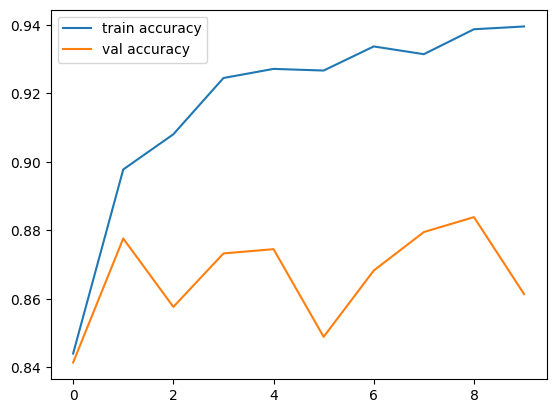

In [12]:
plt.plot(history.history['accuracy'],label = "train accuracy")
plt.plot(history.history['val_accuracy'],label = "val accuracy")
plt.legend()
plt.show()

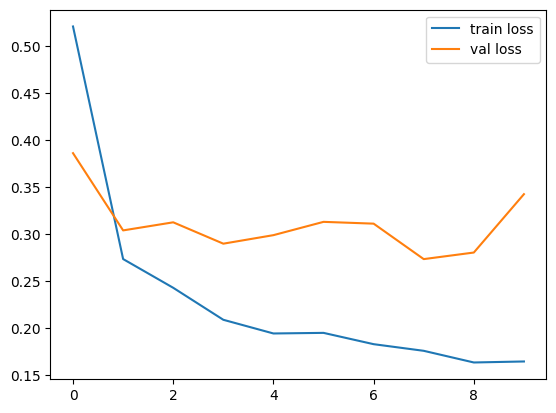

In [13]:
plt.plot(history.history['loss'],label = "train loss")
plt.plot(history.history['val_loss'],label = "val loss")
plt.legend()
plt.show()

In [ ]:
prediction_prob = model.predict(testing_set)

150/150 ━━━━━━━━━━━━━━━━━━━━ 18s 73ms/step


In [15]:
prediction = (prediction_prob > 0.5).astype(int)
prediction

array([[0],
       [0],
       [0],
       ...,
       [1],
       [1],
       [1]], shape=(2400, 1))

In [17]:
true_val = testing_set.classes
true_val

array([0, 0, 0, ..., 1, 1, 1], shape=(2400,), dtype=int32)

In [18]:
print(classification_report(true_val,prediction))
print(confusion_matrix(true_val,prediction))

              precision    recall  f1-score   support

           0       0.99      0.81      0.89      1200
           1       0.84      0.99      0.91      1200

    accuracy                           0.90      2400
   macro avg       0.91      0.90      0.90      2400
weighted avg       0.91      0.90      0.90      2400

[[ 968  232]
 [   9 1191]]


In [19]:
model.save("chest_ct_model.keras")